In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input, RepeatVector, TimeDistributed
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
data = pd.read_csv("energy consumption.csv")

data.head()

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,01-01-2024 00:00,0.457786,0.469524,0.396368,0.445441,0.692057,0
1,01-01-2024 00:30,0.351956,0.465545,0.451184,0.458729,0.539874,0
2,01-01-2024 01:00,0.482948,0.285415,0.408289,0.470360,0.614724,0
3,01-01-2024 01:30,0.628838,0.482095,0.512308,0.576241,0.757044,0
4,01-01-2024 02:00,0.335974,0.624741,0.672021,0.373004,0.673981,0


In [3]:
data["Timestamp"] = pd.to_datetime(data["Timestamp"], dayfirst=True)

data = data.sort_values("Timestamp").reset_index(drop=True)

data = data.fillna(data.median(numeric_only=True))

X = data.drop(["Timestamp", "Anomaly_Label"], axis=1).values
y = data["Anomaly_Label"].values

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (5000, 5)
Y shape: (5000,)


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [5]:
window_size = 10

def create_windows(X, y, window_size):
    X_windows = []
    y_windows = []

    for i in range(len(X) - window_size + 1):
        X_windows.append(X[i:i+window_size])
        y_windows.append(max(y[i:i+window_size]))

    return np.array(X_windows), np.array(y_windows)


X_windows, y_windows = create_windows(
    X_scaled, y, window_size
)

print("Window shape:", X_windows.shape)

Window shape: (4991, 10, 5)


In [6]:
X_normal = X_windows[y_windows == 0]

print("Normal windows:", X_normal.shape)

Normal windows: (3527, 10, 5)


In [7]:
trainX, testX = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

print("TrainX shape:", trainX.shape)
print("TestX shape:", testX.shape)

TrainX shape: (2821, 10, 5)
TestX shape: (706, 10, 5)


In [9]:
model = Sequential([
    Input(shape=(10, 5)),
    LSTM(32, activation="tanh", return_sequences=True),
    LSTM(16, activation="tanh"),
    RepeatVector(10),
    LSTM(32, activation="tanh", return_sequences=True),
    TimeDistributed(Dense(5))
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                        │ (None, 10, 32)              │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 16)                  │           3,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_1 (RepeatVector)       │ (None, 10, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 10, 32)              │           6,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 10, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,437 (56.39 KB)

 Trainable params: 14,437 (56.39 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [11]:
history = model.fit(
    trainX,
    trainX,
    validation_data=(testX, testX),
    batch_size=64,
    epochs=10,
    verbose=1
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.8510 - mae: 0.7302 - val_loss: 0.7928 - val_mae: 0.6990
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7862 - mae: 0.6942 - val_loss: 0.7572 - val_mae: 0.6800
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.7548 - mae: 0.6764 - val_loss: 0.7333 - val_mae: 0.6635
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7362 - mae: 0.6631 - val_loss: 0.7193 - val_mae: 0.6526
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.7231 - mae: 0.6550 - val_loss: 0.7055 - val_mae: 0.6456
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7099 - mae: 0.6484 - val_loss: 0.6944 - val_mae: 0.6396
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6994 - mae: 0.6425 - val_loss: 0.6845 - val_mae: 0.6343
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6887 - mae: 0.6371 - val_loss: 0.6746 - val_mae: 0.6290
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6788 -

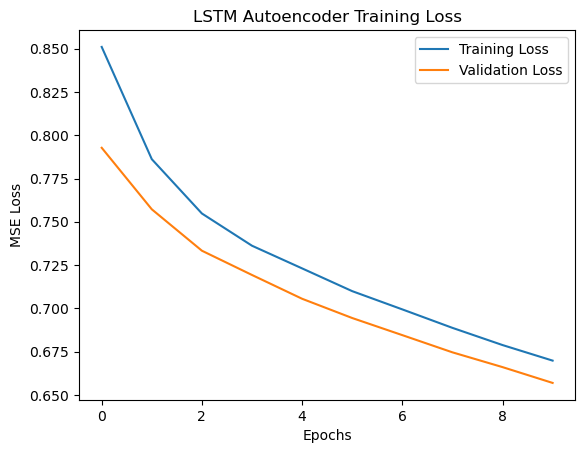

In [12]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("LSTM Autoencoder Training Loss")
plt.legend()
plt.show()

In [13]:
x_reconstruct = model.predict(X_normal, verbose=0)

reconstruction_error = np.mean(np.square(X_normal - x_reconstruct),axis=(1, 2))

print("Reconstruction Error:", reconstruction_error[:10])

Reconstruction Error: [0.48919693 0.50863423 0.56083081 0.57884485 0.55914201 0.51834604
 0.4786741  0.48246547 0.62087113 0.57895733]


In [14]:
x_test_reconstruct = model.predict(testX, verbose=0)

test_error = np.mean(np.square(testX - x_test_reconstruct),axis=(1, 2))

print("Test Reconstruction Error:", test_error[:10])

Test Reconstruction Error: [0.60870365 0.42705666 0.66856384 0.48078469 0.6204729  0.66767916
 0.87298511 0.86438286 0.80311155 0.43741261]


In [15]:
threshold = np.percentile(test_error, 95)

print("Threshold:", threshold)

Threshold: 0.9126281710268569


In [16]:
X_reconstruct = model.predict(X_windows, verbose=0)

all_error = np.mean(np.square(X_windows - X_reconstruct),axis=(1, 2))

y_pred = (all_error > threshold).astype(int)

print("Predicted Classes:", y_pred[:20])

Predicted Classes: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [17]:
print("Confusion Matrix:")
print(confusion_matrix(y_windows, y_pred))

print("\nClassification Report:")
print(classification_report(y_windows, y_pred))

print("Number of anomalies detected:", y_pred.sum())

Confusion Matrix:
[[3330  197]
 [1234  230]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.94      0.82      3527
           1       0.54      0.16      0.24      1464

    accuracy                           0.71      4991
   macro avg       0.63      0.55      0.53      4991
weighted avg       0.67      0.71      0.65      4991

Number of anomalies detected: 427
